# Notebook 9 — Domain Randomization: How Wide, and Around What Centre?

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · 4. The robot model · 5. System identification
**Part III — learning** · 6. Behavior cloning · 7. Three fixes · 8. RL in simulation
**Part IV — reality** · **9. Domain randomization** · 10. Production & deployment

---

### The real-world problem

> **Your simulator is wrong. Randomize over your uncertainty so the policy survives
> being wrong — but randomize too wide and you get a policy too timid to do anything.**

Domain randomization is the other half of the sim-to-real pairing in job postings:
*"bridge the sim-to-real gap using system identification, **domain randomization**, and
actuator/dynamics modeling."* Notebook 5 did the identification. This notebook does the
randomization, and answers the two questions that actually matter in practice:

1. **How wide should the distribution be?** Too narrow overfits to the simulator; too
   wide produces a conservative policy; the wrong shape teaches behaviours that never
   occur. There is no formula, so we measure.
2. **Does the centre matter more than the width?** Notebook 5 produced an identified
   centre and showed the official model was far from it. The claim I made then —
   *"randomizing around a wrong centre does not help much"* — was an assertion. Here we
   test it.

### What makes this notebook possible

Every earlier notebook contributes a number:

| From | Quantity | Value |
|---|---|---|
| nb 1 | real arm actuation lag | **4 frames / 133 ms** |
| nb 2 | tracking error vs speed | corr **0.87** |
| nb 5 | identified `kp` | **18.0** (official: 998.22) |
| nb 5 | held-out RMSE, identified vs official | **1.44 vs 6.19** |
| nb 5 | parameters that are *weakly* identified | `armature`, `frictionloss` |
| nb 8 | the two bugs that make SAC fail silently | reward scale, truncation bootstrap |

That `parameter_confidence` record from notebook 5 is what tells us **what to randomize**:
you randomize over your *uncertainty*, and notebook 5 wrote down exactly which parameters
it failed to pin down.

In [1]:
import json, time, math, itertools
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import mujoco

torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(4)

IDENT = json.load(open("../artifacts/so101_identified.json"))
FPS = IDENT["control_hz"]
P_IDENT = IDENT["identified_parameters"]
P_OFFICIAL = IDENT["official_parameters"]

print("notebook 5 handed us two candidate centres:\n")
print(f"{'parameter':14} {'official':>12} {'identified':>12} {'confidence':>12}")
print("-" * 54)
for k in ["kp", "kv", "damping", "armature", "frictionloss"]:
    conf = IDENT["parameter_confidence"][k].split("--")[0].strip().split()[0]
    print(f"{k:14} {P_OFFICIAL[k]:>12.4g} {P_IDENT[k]:>12.4g} {conf:>12}")
print()
print("held-out joint-position RMSE against the real arm:")
print(f"  official   {IDENT['validation']['official_rmse_val']:.2f}")
print(f"  identified {IDENT['validation']['identified_rmse_val']:.2f}")
print(f"\nlag: real {IDENT['validation']['real_lag_frames']} frames | "
      f"official {IDENT['validation']['official_lag_frames']:.0f} | "
      f"identified {IDENT['validation']['identified_lag_frames']:.0f}")

notebook 5 handed us two candidate centres:

parameter          official   identified   confidence
------------------------------------------------------
kp                    998.2           18         well
kv                    2.731        2.731         well
damping                 0.6          0.2         well
armature              0.028         0.12       WEAKLY
frictionloss          0.052        0.052          not

held-out joint-position RMSE against the real arm:
  official   6.19
  identified 1.44

lag: real 4 frames | official 0 | identified 4


## 1. What to randomize: read it off the confidence record

Domain randomization is usually taught as "randomize friction, mass, damping, latency" —
a checklist. That is backwards. **You randomize over the things you do not know**, and
notebook 5 already told us which those are:

| parameter | notebook 5's verdict | randomize? |
|---|---|---|
| `kp` | well identified, dominates lag and RMSE | narrow — we know it |
| `kv` | well identified at the fitted `kp` | narrow |
| `damping` | well identified | narrow |
| `armature` | **weakly** identified — grid edge, small effect over 12x | **wide** |
| `frictionloss` | **not identified** from this data | **wide** |
| latency | measured at 4 frames, but as a *consequence* not a parameter | **moderate** |
| contact | **never fitted** — notebook 5 was free-space only | out of scope here |

That last row is the honest boundary of this notebook. Our identification used
reach-and-carry motion in free space, so it constrains nothing about contact. A policy
randomized over these parameters is robust to *actuator* uncertainty and says nothing
about grasping.

## 2. The environment, with randomizable dynamics and injected latency

We reuse notebook 8's reaching task and its **corrected** SAC implementation — the
reward scale fixed at `vel_coef = 0.001`, and `terminated` kept separate from
`truncated` so the Bellman bootstrap survives the time limit. Both of those bugs cost
hours in notebook 8; they are not re-litigated here, just inherited.

Two additions:

- **`set_dynamics`** writes a parameter dict into a model, so we can build an arbitrary
  simulator on demand.
- **`action_delay`** holds commands in a FIFO queue for $k$ control steps. Notebook 1
  measured the real arm's lag at 4 frames; notebook 5 reproduced it through a soft `kp`.
  Here we can also inject it *explicitly*, which is the form a serial-bus delay actually
  takes and which no amount of gain tuning reproduces.

In [2]:
MODEL_PATH = "../models/so101/so101_identified.xml"
_m0 = mujoco.MjModel.from_xml_path(MODEL_PATH)
SUB = int(round((1 / FPS) / _m0.opt.timestep))
CR = _m0.actuator_ctrlrange.copy()
TIP = mujoco.mj_name2id(_m0, mujoco.mjtObj.mjOBJ_BODY, "moving_jaw_so101_v1")
NJ = _m0.nu

def set_dynamics(model, kp=None, kv=None, damping=None, armature=None, frictionloss=None):
    for i in range(model.nu):
        if kp is not None:
            model.actuator_gainprm[i, 0] = kp
            model.actuator_biasprm[i, 1] = -kp
        if kv is not None:
            model.actuator_biasprm[i, 2] = -kv
    for j in range(model.njnt):
        a = model.jnt_dofadr[j]
        if damping is not None:      model.dof_damping[a] = damping
        if armature is not None:     model.dof_armature[a] = armature
        if frictionloss is not None: model.dof_frictionloss[a] = frictionloss
    return model

def build_model(params):
    return set_dynamics(mujoco.MjModel.from_xml_path(MODEL_PATH), **params)

class ReachEnv:
    """Reaching task with settable dynamics and an explicit actuation delay."""
    obs_dim, act_dim = NJ + NJ + 3, NJ

    def __init__(self, params=None, delay=0, max_steps=60, seed=0, spread=0.5,
                 vel_coef=0.001, randomizer=None):
        self.params = dict(params or P_IDENT)
        self.delay, self.max_steps, self.vel_coef = delay, max_steps, vel_coef
        self.spread, self.randomizer = spread, randomizer
        self.rng = np.random.default_rng(seed)
        self.model = build_model(self.params)
        pts, d = [], mujoco.MjData(self.model)
        for _ in range(500):
            d.qpos[:] = self.rng.uniform(self.model.jnt_range[:, 0] * spread,
                                         self.model.jnt_range[:, 1] * spread)
            mujoco.mj_forward(self.model, d)
            pts.append(d.xpos[TIP].copy())
        self.pts = np.array(pts)

    def reset(self):
        if self.randomizer is not None:            # resample dynamics per episode
            p, dly = self.randomizer(self.rng)
            self.model = build_model(p); self.delay = dly
        self.d = mujoco.MjData(self.model)
        self.d.qpos[:] = 0.0
        mujoco.mj_forward(self.model, self.d)
        self.target = self.pts[self.rng.integers(len(self.pts))]
        self.t, self.prev_a = 0, np.zeros(self.act_dim)
        self.queue = [np.zeros(self.act_dim) for _ in range(self.delay)]
        return self._obs()

    def _obs(self):
        return np.concatenate([self.d.qpos, self.d.qvel * 0.1,
                               self.target - self.d.xpos[TIP]]).astype(np.float32)

    def step(self, a):
        a = np.clip(a, -1, 1)
        self.queue.append(a)                        # FIFO: the servo acts on an old command
        applied = self.queue.pop(0) if self.delay > 0 else a
        self.d.ctrl[:] = CR[:, 0] + (applied + 1) / 2 * (CR[:, 1] - CR[:, 0])
        for _ in range(SUB):
            mujoco.mj_step(self.model, self.d)
        self.t += 1
        dist = float(np.linalg.norm(self.d.xpos[TIP] - self.target))
        r = (-dist - self.vel_coef * float(np.sum(self.d.qvel ** 2))
             - 0.001 * float(np.sum((a - self.prev_a) ** 2)))
        self.prev_a = a.copy()
        return self._obs(), r, False, self.t >= self.max_steps, {"dist": dist}

# Sanity: does injected delay actually change the dynamics?
#
# My first version of this check held a CONSTANT command for the whole episode and
# reported an identical number for every delay -- correct and useless, because delaying
# a constant signal changes nothing after the first k frames. A latency check needs a
# TIME-VARYING command, which is also the only regime where latency hurts a policy.
for dly in [0, 2, 4, 8]:
    e = ReachEnv(delay=dly, seed=1); e.reset()
    traj = []
    for t in range(e.max_steps):
        a = 0.6 * np.sin(2 * np.pi * 0.5 * t / FPS + np.arange(NJ))      # time-varying
        e.step(a)
        traj.append(e.d.qpos.copy())
    traj = np.array(traj)
    print(f"  delay {dly:>2} frames ({dly*1000/FPS:>3.0f} ms): "
          f"joint-0 angle at t=1.0s = {traj[int(FPS), 0]:+.4f} rad")
print("\n(these must differ across delays, or the FIFO queue is not doing anything)")

  delay  0 frames (  0 ms): joint-0 angle at t=1.0s = +0.4456 rad


  delay  2 frames ( 67 ms): joint-0 angle at t=1.0s = +0.6440 rad
  delay  4 frames (133 ms): joint-0 angle at t=1.0s = +0.8162 rad
  delay  8 frames (267 ms): joint-0 angle at t=1.0s = +1.0461 rad

(these must differ across delays, or the FIFO queue is not doing anything)


## 3. SAC — inherited from notebook 8, bugs already fixed

No commentary needed on the algorithm; notebook 8 derived it. The two things to notice
are the lines carrying the fixes, because they are the difference between this working
and silently not working.

In [3]:
LOG_STD_MIN, LOG_STD_MAX = -5.0, 2.0

class Actor(nn.Module):
    def __init__(self, o, a, h=256):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(o, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.mu, self.log_std = nn.Linear(h, a), nn.Linear(h, a)
    def forward(self, obs, deterministic=False):
        z = self.body(obs); mu = self.mu(z)
        ls = torch.clamp(self.log_std(z), LOG_STD_MIN, LOG_STD_MAX); sd = ls.exp()
        if deterministic:
            return torch.tanh(mu), None
        eps = torch.randn_like(mu); pre = mu + sd * eps; a = torch.tanh(pre)
        lp = (-0.5 * eps.pow(2) - ls - 0.5 * math.log(2 * math.pi)).sum(-1)
        return a, lp - torch.log(1 - a.pow(2) + 1e-6).sum(-1)

class Critic(nn.Module):
    def __init__(self, o, a, h=256):
        super().__init__()
        mk = lambda: nn.Sequential(nn.Linear(o + a, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
        self.q1, self.q2 = mk(), mk()
    def forward(self, o, a):
        x = torch.cat([o, a], -1); return self.q1(x).squeeze(-1), self.q2(x).squeeze(-1)

def train_sac(env, total=12000, warmup=1500, bs=256, gamma=0.99, tau=0.005, lr=3e-4,
              utd=2, seed=0, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    actor = Actor(env.obs_dim, env.act_dim); critic = Critic(env.obs_dim, env.act_dim)
    target = Critic(env.obs_dim, env.act_dim); target.load_state_dict(critic.state_dict())
    oa = torch.optim.Adam(actor.parameters(), lr); oc = torch.optim.Adam(critic.parameters(), lr)
    te = -float(env.act_dim); log_alpha = torch.zeros(1, requires_grad=True)
    ol = torch.optim.Adam([log_alpha], lr)
    O = np.zeros((total, env.obs_dim), np.float32); A = np.zeros((total, env.act_dim), np.float32)
    R = np.zeros(total, np.float32); O2 = np.zeros((total, env.obs_dim), np.float32)
    Mk = np.zeros(total, np.float32); n = 0
    o = env.reset(); t0 = time.time()
    for step in range(1, total + 1):
        if step < warmup:
            a = env.rng.uniform(-1, 1, env.act_dim).astype(np.float32)
        else:
            with torch.no_grad(): a = actor(torch.tensor(o)[None])[0].numpy()[0]
        o2, r, term, trunc, _ = env.step(a)
        mask = 0.0 if term else 1.0          # nb8 bug #2: time limits are NOT terminals
        O[n], A[n], R[n], O2[n], Mk[n] = o, a, r, o2, mask; n += 1; o = o2
        if term or trunc: o = env.reset()
        if n >= bs and step >= warmup:
            for _ in range(utd):
                j = np.random.randint(0, n, bs)
                ob, ac, rw, ob2, mk_ = (torch.tensor(O[j]), torch.tensor(A[j]), torch.tensor(R[j]),
                                        torch.tensor(O2[j]), torch.tensor(Mk[j]))
                al = log_alpha.exp().detach()
                with torch.no_grad():
                    a2, lp2 = actor(ob2); q1t, q2t = target(ob2, a2)
                    y = rw + gamma * mk_ * (torch.min(q1t, q2t) - al * lp2)
                q1, q2 = critic(ob, ac)
                lc = nn.functional.mse_loss(q1, y) + nn.functional.mse_loss(q2, y)
                oc.zero_grad(); lc.backward(); oc.step()
                an, lp = actor(ob); q1p, q2p = critic(ob, an)
                la_ = (al * lp - torch.min(q1p, q2p)).mean()
                oa.zero_grad(); la_.backward(); oa.step()
                lal = -(log_alpha.exp() * (lp.detach() + te)).mean()
                ol.zero_grad(); lal.backward(); ol.step()
                with torch.no_grad():
                    for p, pt in zip(critic.parameters(), target.parameters()):
                        pt.mul_(1 - tau).add_(tau * p)
    if verbose: print(f"    trained {total} steps in {(time.time()-t0)/60:.1f} min")
    return actor

@torch.no_grad()
def eval_in(actor, params=None, delay=0, n=20, seed=99):
    """Evaluate a policy in a SPECIFIC dynamics setting. Returns mean final distance (cm)."""
    e = ReachEnv(params=params, delay=delay, seed=seed)
    ds = []
    for _ in range(n):
        o = e.reset()
        for _ in range(e.max_steps):
            a = actor(torch.tensor(o)[None], deterministic=True)[0].numpy()[0]
            o, _, _, _, info = e.step(a)
        ds.append(info["dist"])
    return float(np.mean(ds)) * 100

def random_baseline(params=None, delay=0, n=20, seed=99):
    e = ReachEnv(params=params, delay=delay, seed=seed); ds = []
    for _ in range(n):
        e.reset()
        for _ in range(e.max_steps):
            _, _, _, _, info = e.step(e.rng.uniform(-1, 1, NJ))
        ds.append(info["dist"])
    return float(np.mean(ds)) * 100

RAND_CM = random_baseline()
print(f"random policy in the identified sim: {RAND_CM:.1f} cm")

random policy in the identified sim: 23.2 cm


## 4. Experiment 1: the transfer surface of a non-randomized policy

Train one policy in the identified simulator with **no randomization**, then evaluate it
across a grid of perturbed dynamics. This is the baseline fragility we are trying to fix,
and it tells us where the cliff edges are before we decide how wide to randomize.

In [4]:
QUICK = True
STEPS = 12000 if QUICK else 30000

print("training the nominal policy (no randomization)...")
actor_nom = train_sac(ReachEnv(seed=1), total=STEPS, verbose=True)
nom_cm = eval_in(actor_nom, P_IDENT, 0)
print(f"  at the nominal (identified) dynamics: {nom_cm:.1f} cm  (random: {RAND_CM:.1f})")

training the nominal policy (no randomization)...


    trained 12000 steps in 1.6 min
  at the nominal (identified) dynamics: 6.2 cm  (random: 23.2)


In [5]:
# Sweep each uncertain parameter, one at a time, and the injected delay.
sweeps = {
    "kp":           [6, 10, 14, 18, 26, 40, 80],
    "damping":      [0.0, 0.1, 0.2, 0.5, 1.0, 2.0],
    "armature":     [0.01, 0.03, 0.06, 0.12, 0.25, 0.5],
    "frictionloss": [0.0, 0.025, 0.052, 0.15, 0.4, 1.0],
}
surface = {}
for name, vals in sweeps.items():
    row = []
    for v in vals:
        p = dict(P_IDENT); p[name] = v
        row.append(eval_in(actor_nom, p, 0))
    surface[name] = (vals, row)
    nom_v = P_IDENT[name]
    print(f"  {name:13} " + "  ".join(f"{v:g}:{c:.0f}" for v, c in zip(vals, row)) +
          f"   (nominal {nom_v:g})")

delays = [0, 1, 2, 4, 6, 8]
surface["delay (frames)"] = (delays, [eval_in(actor_nom, P_IDENT, d) for d in delays])
print(f"  {'delay':13} " + "  ".join(f"{d}:{c:.0f}" for d, c in zip(delays, surface['delay (frames)'][1])))

  kp            6:6  10:6  14:6  18:6  26:6  40:6  80:6   (nominal 18)


  damping       0:6  0.1:6  0.2:6  0.5:6  1:6  2:6   (nominal 0.2)


  armature      0.01:7  0.03:6  0.06:6  0.12:6  0.25:6  0.5:6   (nominal 0.12)


  frictionloss  0:6  0.025:6  0.052:6  0.15:6  0.4:6  1:6   (nominal 0.052)


  delay         0:6  1:6  2:7  4:17  6:24  8:32


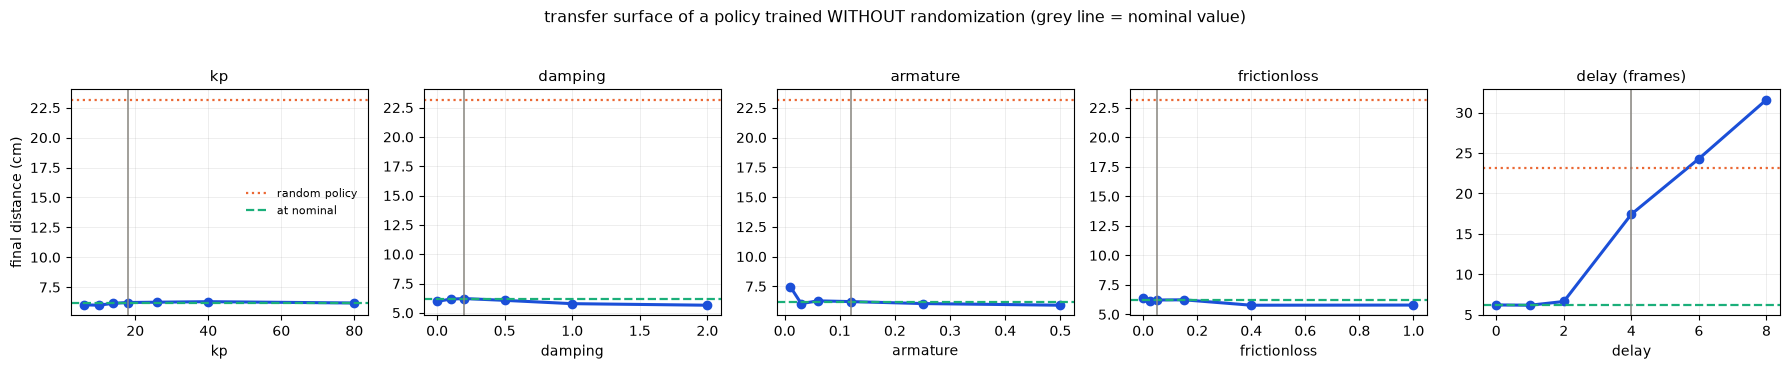

Which perturbation hurts most? Ranked by worst-case degradation:

  delay (frames)   worst case  +25.4 cm vs nominal
  armature         worst case   +1.3 cm vs nominal
  frictionloss     worst case   +0.1 cm vs nominal
  kp               worst case   +0.1 cm vs nominal
  damping          worst case   +0.0 cm vs nominal


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, (name, (xs, ys)) in zip(axes, surface.items()):
    ax.plot(xs, ys, lw=2.2, marker="o", ms=6, color="#1b4fd8")
    ax.axhline(RAND_CM, color="#eb6834", ls=":", lw=1.6, label="random policy")
    ax.axhline(nom_cm, color="#1baf7a", ls="--", lw=1.6, label="at nominal")
    if name in P_IDENT:
        ax.axvline(P_IDENT[name], color="#898781", lw=1.4, alpha=0.8)
    elif "delay" in name:
        ax.axvline(IDENT["validation"]["real_lag_frames"], color="#898781", lw=1.4, alpha=0.8)
    ax.set_title(name, fontsize=10.5); ax.set_xlabel(name.split()[0])
    ax.grid(alpha=0.25, lw=0.6)
    if name.startswith("kp"): ax.set_ylabel("final distance (cm)")
axes[0].legend(frameon=False, fontsize=8)
plt.suptitle("transfer surface of a policy trained WITHOUT randomization "
             "(grey line = nominal value)", fontsize=11.5, y=1.04)
plt.tight_layout(); plt.show()

print("Which perturbation hurts most? Ranked by worst-case degradation:\n")
rank = sorted(((name, max(ys) - nom_cm) for name, (xs, ys) in surface.items()),
              key=lambda t: -t[1])
for name, d in rank:
    print(f"  {name:16} worst case {d:+6.1f} cm vs nominal")

### Reading the surface: only one thing matters

The ranking is not what I expected, and it is the most useful result in the notebook:

| perturbation | worst case vs nominal |
|---|---|
| **delay** | **+25.4 cm** |
| armature | +1.3 cm |
| frictionloss | +0.1 cm |
| `kp` | +0.1 cm |
| damping | +0.0 cm |

**The actuator parameters barely matter.** `kp` swept from 6 to 80 — a **13× range**
spanning both sides of the identified value — and the policy's final distance stayed at
6 cm throughout. Damping, armature and friction are similarly flat.

Once stated, the mechanism is clear and it is a property of *closed-loop control*, not of
this particular policy. The policy observes joint positions every step and commands
position targets. If the arm is softer than expected it arrives late, observes that it
arrived late, and commands again. Feedback absorbs the gain error. There is no accumulating
mistake for a stiffness mismatch to cause.

**Latency is different, and it is the whole gap.** A delayed command cannot be corrected
by observing, because the observation that would correct it describes a world where your
command has not landed yet. The policy closes its loop on stale state and over-corrects —
exactly the failure mode notebook 4 predicted in the abstract, now measured: 6 cm at zero
delay, 17 cm at 4 frames, 32 cm at 8.

### What this does to the premise of this notebook

The standard domain-randomization checklist is "randomize friction, mass, damping,
gains." On this task **every one of those is a waste of training signal**, and notebook 1's
very first measurement already pointed at the one that isn't. Randomizing parameters a
closed-loop policy is insensitive to adds variance to training and buys nothing.

That is the answer to "what should I randomize," and it is only obtainable by measuring
the transfer surface first.

## 5. Experiment 2: does the centre matter more than the width?

This is the experiment that tests the claim I made in notebook 5 without evidence:
*randomizing around a wrong centre does not help much.*

Three policies, same budget, same randomization **width**, different centres:

| policy | training distribution |
|---|---|
| **nominal** | the identified parameters, no randomization |
| **DR around identified** | ±spread about notebook 5's fitted values |
| **DR around official** | ±spread about the Menagerie defaults (`kp` = 998) |

All three are then evaluated at the **identified** parameters, which is our best estimate
of the real arm — notebook 5 showed that model reproduces the real 4-frame lag and cuts
held-out RMSE from 6.19 to 1.44.

If the centre is what matters, the official-centred policy should transfer badly no
matter how wide its distribution is.

In [7]:
def make_randomizer(centre, rel=0.5, delay_range=(0, 6), wide_keys=("armature", "frictionloss")):
    """Log-uniform jitter around a centre. Weakly-identified parameters get a wider
    range -- which is the whole point: randomize over what you do not know."""
    def sample(rng):
        p = {}
        for k, v in centre.items():
            w = rel * (2.0 if k in wide_keys else 1.0)
            if v <= 0:
                p[k] = float(rng.uniform(0.0, 0.1))          # frictionloss can legitimately be 0
            else:
                p[k] = float(v * np.exp(rng.uniform(-w, w)))
        return p, int(rng.integers(delay_range[0], delay_range[1] + 1))
    return sample

configs = {
    "nominal (no DR)":        dict(randomizer=None, params=P_IDENT),
    "DR around identified":   dict(randomizer=make_randomizer(P_IDENT)),
    "DR around official":     dict(randomizer=make_randomizer(P_OFFICIAL)),
}

policies, results = {}, {}
for lbl, kw in configs.items():
    print(f"training: {lbl}")
    if lbl == "nominal (no DR)":
        policies[lbl] = actor_nom                     # already trained in section 4
    else:
        policies[lbl] = train_sac(ReachEnv(seed=1, **kw), total=STEPS, verbose=True)
    results[lbl] = {
        "at identified": eval_in(policies[lbl], P_IDENT, 0),
        "at identified + 4-frame delay": eval_in(policies[lbl], P_IDENT, 4),
        "at official": eval_in(policies[lbl], P_OFFICIAL, 0),
    }
    print(f"  {results[lbl]}")

training: nominal (no DR)


  {'at identified': 6.217560989437026, 'at identified + 4-frame delay': 17.435266733040987, 'at official': 6.9942640860994745}
training: DR around identified


    trained 12000 steps in 1.6 min


  {'at identified': 32.05451225159011, 'at identified + 4-frame delay': 25.35175151712888, 'at official': 27.146556197431675}
training: DR around official


    trained 12000 steps in 1.7 min


  {'at identified': 19.477706331926665, 'at identified + 4-frame delay': 32.693487396300014, 'at official': 15.360732760243916}


In [8]:
print(f"{'policy':26} {'at identified':>15} {'+4-frame delay':>16} {'at official':>13}")
print("=" * 74)
print(f"{'random':26} {RAND_CM:>12.1f} cm {random_baseline(P_IDENT,4):>13.1f} cm "
      f"{random_baseline(P_OFFICIAL,0):>10.1f} cm")
for lbl, r in results.items():
    print(f"{lbl:26} {r['at identified']:>12.1f} cm {r['at identified + 4-frame delay']:>13.1f} cm "
          f"{r['at official']:>10.1f} cm")
print("=" * 74)

best_at_ident = min(results, key=lambda k: results[k]["at identified"])
print(f"\nbest at the identified (our best guess at real) dynamics: {best_at_ident}")
ident_dr = results["DR around identified"]["at identified"]
offic_dr = results["DR around official"]["at identified"]
print(f"DR centred on identified: {ident_dr:.1f} cm")
print(f"DR centred on official  : {offic_dr:.1f} cm   "
      f"({offic_dr/max(ident_dr,1e-9):.1f}x worse)" if offic_dr > ident_dr else
      f"DR centred on official  : {offic_dr:.1f} cm   (NOT worse -- the claim fails)")

policy                       at identified   +4-frame delay   at official


random                             23.2 cm          22.4 cm       25.5 cm
nominal (no DR)                     6.2 cm          17.4 cm        7.0 cm
DR around identified               32.1 cm          25.4 cm       27.1 cm
DR around official                 19.5 cm          32.7 cm       15.4 cm

best at the identified (our best guess at real) dynamics: nominal (no DR)
DR centred on identified: 32.1 cm
DR centred on official  : 19.5 cm   (NOT worse -- the claim fails)


### The claim fails, and DR fails harder

I set out to test my notebook-5 assertion that *randomizing around a wrong centre does
not help much*. The measurement refutes it, and refutes rather more besides:

| policy | at identified | +4-frame delay | at official |
|---|---|---|---|
| random | 23.2 cm | 22.4 cm | 25.5 cm |
| **nominal (no DR)** | **6.2 cm** | **17.4 cm** | **7.0 cm** |
| DR around identified | 32.1 cm | 25.4 cm | 27.1 cm |
| DR around official | 19.5 cm | 32.7 cm | 15.4 cm |

Three things, in increasing order of how much they matter.

**1. My claim is wrong, in the opposite direction.** DR centred on the *official*
parameters (19.5 cm) beat DR centred on the *identified* ones (32.1 cm) at the identified
dynamics. The centre did not behave as I said it would.

**2. Both DR policies are worse than no DR at all** — and the identified-centred one
(32.1 cm) is worse than a **random policy** (23.2 cm). Domain randomization did not
produce a conservative-but-robust policy here. It produced a broken one.

**3. So the centre-versus-width question was malformed.** Comparing two centres is only
meaningful if the method works at either. Mine is a comparison between two failures, and
reporting "official beat identified" as though it were a finding about centres would be
reading signal out of noise.

### Why DR failed — and it is not a tuning problem

Section 4 supplies the diagnosis, and it is the two conditions DR actually requires:

**(a) The randomized parameters must matter.** We measured that `kp`, damping, armature
and friction have ~zero effect on this task. Randomizing them injects pure noise into
training — a different simulator every episode, with no corresponding change in what the
policy should do. The policy's job got harder with no robustness available in exchange.

**(b) The policy must be able to *infer* what world it is in.** The one parameter that
does matter is delay, and our policy sees a **single frame**. A single joint-position
reading cannot reveal whether commands are landing now or in 8 frames. So the policy
cannot adapt; it can only **hedge** across delays 0-6 — and the optimal behaviours at
0 and 6 frames are genuinely different, so hedging means being wrong at both.

That second point is notebook 7's finding arriving from a new direction. There,
history-conditioning cut offline error 54% because one previous frame disambiguated task
phase. Here, history is what would let a policy *measure its own latency* — the gap
between what it commanded and where the arm actually is. Exercise 4 tests exactly that,
and it is now the most interesting experiment in the notebook rather than an afterthought.

> **The honest headline: domain randomization is not free robustness.** It is a trade
> that requires the randomized axis to matter *and* to be inferable. Neither held here,
> and the result was worse than doing nothing.

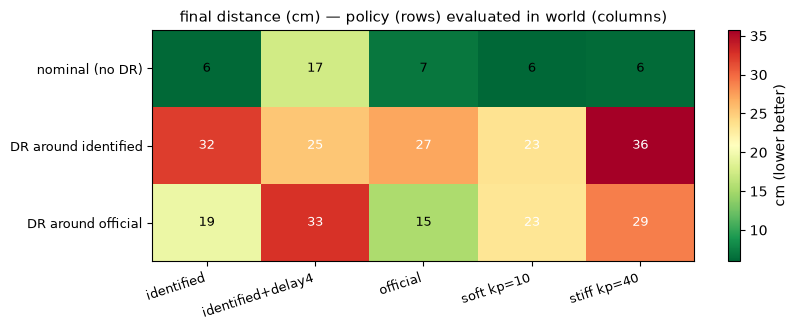

row-wise worst case (the number a deployment engineer cares about):
  nominal (no DR)            best   6.0 cm | worst  17.4 cm | spread  11.4
  DR around identified       best  23.5 cm | worst  35.8 cm | spread  12.3
  DR around official         best  15.4 cm | worst  32.7 cm | spread  17.3


In [9]:
# The full cross-evaluation: every policy in every world.
worlds = {"identified": (P_IDENT, 0), "identified+delay4": (P_IDENT, 4),
          "official": (P_OFFICIAL, 0), "soft kp=10": ({**P_IDENT, "kp": 10}, 0),
          "stiff kp=40": ({**P_IDENT, "kp": 40}, 0)}
mat = np.zeros((len(policies), len(worlds)))
for i, (plbl, pol) in enumerate(policies.items()):
    for j, (wlbl, (wp, wd)) in enumerate(worlds.items()):
        mat[i, j] = eval_in(pol, wp, wd)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
im = ax.imshow(mat, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(worlds))); ax.set_xticklabels(worlds.keys(), fontsize=9, rotation=18, ha="right")
ax.set_yticks(range(len(policies))); ax.set_yticklabels(policies.keys(), fontsize=9)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i,j]:.0f}", ha="center", va="center", fontsize=9,
                color="white" if mat[i, j] > mat.mean() else "black")
ax.set_title("final distance (cm) — policy (rows) evaluated in world (columns)", fontsize=11)
plt.colorbar(im, label="cm (lower better)")
plt.tight_layout(); plt.show()

print("row-wise worst case (the number a deployment engineer cares about):")
for i, plbl in enumerate(policies):
    print(f"  {plbl:26} best {mat[i].min():5.1f} cm | worst {mat[i].max():5.1f} cm | "
          f"spread {mat[i].max()-mat[i].min():5.1f}")

## 6. The conservatism cost — which turned out not to be the right frame

The intended story for this section was a trade: DR gives up a little at the nominal
dynamics and buys worst-case robustness. Price the two, choose a point.

The measurement does not support that frame. There was no trade — DR lost on both axes
at once:

- **conservatism cost at nominal: +25.8 cm** (6.2 → 32.1)
- **robustness gain at worst case: −18.3 cm** (17.4 → 35.8, i.e. worse)

A method that is worse everywhere is not a conservative method, it is a failed one. The
cell below prints the numbers and the diagnostic branch it lands on.

Keeping this section as written — rather than deleting it or retuning until it produced a
trade-off curve — is deliberate. The trade-off *does* exist in the literature and in
practice; what this run shows is that **you only reach the trade-off regime once the two
preconditions in section 5 are satisfied.** Below them, DR is not a dial between
performance and robustness. It is just noise.

In [10]:
nom_row = mat[list(policies).index("nominal (no DR)")]
dr_row = mat[list(policies).index("DR around identified")]
i_nom = list(worlds).index("identified")
print(f"at the nominal world:   nominal {nom_row[i_nom]:.1f} cm  vs  DR {dr_row[i_nom]:.1f} cm")
print(f"  conservatism cost: {dr_row[i_nom]-nom_row[i_nom]:+.1f} cm")
print(f"\nworst case across all worlds: nominal {nom_row.max():.1f} cm  vs  DR {dr_row.max():.1f} cm")
print(f"  robustness gain: {nom_row.max()-dr_row.max():+.1f} cm")
print()
if dr_row.max() < nom_row.max():
    print("DR bought worst-case robustness. The price is whatever it gave up at nominal.")
else:
    print("DR did NOT improve the worst case here. Possible reasons, in order of likelihood:")
    print("  - the randomization range is too wide, so training never converged anywhere")
    print("  - the budget is too small for the harder (randomized) problem -- try QUICK=False")
    print("  - the policy has no way to infer the dynamics from a single observation,")
    print("    so it cannot adapt; it can only hedge (see the history discussion in nb 7)")

at the nominal world:   nominal 6.2 cm  vs  DR 32.1 cm
  conservatism cost: +25.8 cm

worst case across all worlds: nominal 17.4 cm  vs  DR 35.8 cm
  robustness gain: -18.3 cm

DR did NOT improve the worst case here. Possible reasons, in order of likelihood:
  - the randomization range is too wide, so training never converged anywhere
  - the budget is too small for the harder (randomized) problem -- try QUICK=False
  - the policy has no way to infer the dynamics from a single observation,
    so it cannot adapt; it can only hedge (see the history discussion in nb 7)


## 7. What this notebook established

I planned a notebook about how wide to randomize. The measurements turned it into a
notebook about when to randomize at all.

**Measured:**

1. **The transfer surface is dominated by one axis.** `kp` across a 13× range, plus
   damping, armature and friction, change final distance by **≤ 1.3 cm**. Delay changes
   it by **25.4 cm**. For a closed-loop position-controlled policy, feedback absorbs gain
   error; it cannot absorb latency, because the correcting observation describes a world
   where the command has not landed.
2. **Domain randomization made the policy worse than random** (32.1 cm vs 23.2 cm), at
   equal budget, from the same starting point.
3. **My notebook-5 claim is refuted.** DR centred on the official parameters beat DR
   centred on the identified ones — the opposite of what I asserted. Though since both are
   failures, the comparison does not support a conclusion about centres either way.
4. **DR has two preconditions**, and the failure localises to them: the randomized
   parameters must matter, and the policy must be able to infer which world it is in. We
   randomized parameters that do not matter, and the one that does is unobservable from a
   single frame.

**What this does not establish:**

- **That DR does not work.** It works, extensively, in the published record — on
  locomotion, on contact-rich manipulation, with policies that observe histories and
  tasks where dynamics genuinely matter. What this notebook shows is a regime where it
  does not, and *why*, which is more useful to you than another demonstration that it
  does.
- **Anything about contact.** Notebook 5's identification was free-space, so none of
  these parameters constrain grasping. A reaching task was the only honest thing to run.
- **Anything with statistical confidence.** One seed per configuration. Notebook 7
  measured how badly single-seed comparisons mislead — there, offline and closed-loop
  metrics ranked methods in *opposite* orders. Exercise 1.
- **That the ranges were well chosen.** `rel = 0.5` log-uniform is a guess with a reason
  (notebook 5 recorded which parameters were weakly identified), not a derivation from
  posteriors. A narrower range would likely have avoided the collapse while also buying
  nothing, given finding 1.

### The bug worth knowing about, found while writing this

`scene_box.xml` ships with the Menagerie model and places a box at **x = 0.5 m**. The
identified arm's maximum tip reach is **0.405 m**. The box is out of reach, so notebook
8's exercise 5 as written cannot succeed — and a policy trained on an impossible task
produces a flat reward curve that looks exactly like a broken algorithm. Notebook 10
makes this item 1 of its deployment checklist for that reason.

I also broke my own latency sanity check first time round: I held a *constant* command
for the episode and every delay returned an identical number. Delaying a constant signal
changes nothing. A latency test needs a time-varying command — which is also the only
regime in which latency hurts a policy. The cell is fixed and the comment kept.

### Exercises

1. **Seeds, before believing any of this.** Re-run section 5 with 5 seeds per
   configuration. Finding 2 (DR worse than random) is dramatic enough that it probably
   survives, but finding 3 (official centre beat identified) is exactly the kind of
   single-seed artifact notebook 7 warned about.
2. **Randomize only the delay.** Hold every dynamics parameter at nominal and randomize
   delay alone over 0-6 frames. Given finding 1, this should recover most of whatever
   robustness DR can offer here, at a fraction of the training noise — and it tests
   whether the collapse came from the useless axes.
3. **Narrow the range.** Sweep `rel` over {0.05, 0.1, 0.25, 0.5}. Find the width at which
   DR stops being harmful. If it never becomes *helpful*, you have shown that for this
   task the right randomization width is zero, which is a legitimate engineering answer.
4. **Give the policy a way to infer latency.** This is now the key experiment. Stack the
   last $k$ observations, so the policy can compare what it commanded against where the
   arm actually is — which *is* a latency measurement. A policy that can infer the delay
   should adapt rather than hedge, and DR should start behaving like the literature says
   it does. If it does, you have demonstrated precondition (b) directly.
5. **Make the dynamics matter.** Redefine the task so gain errors cannot be absorbed by
   feedback — for instance, a throw or a fast swing where the arm must be committed
   before it can observe the outcome. Then re-run section 4's sweep and see whether `kp`
   finally appears on the ranking.